# Evaluation & Explainability

Full evaluation on held-out test set — ROC, precision-recall, confusion matrix.
Then SHAP to understand what the model is actually picking up on.

In [1]:
import pandas as pd
import numpy as np
import joblib
import shap
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)
from imblearn.over_sampling import SMOTE

sns.set_theme(style='whitegrid')
%matplotlib inline

TARGET   = 'SeriousDlqin2yrs'
DROP_COLS = ['monthly_debt', 'income_per_dependent']

c:\Users\Agam Katiyar\Projects\loan-risk-ml\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Recreate train/test split

Same seed as notebook 03 — identical split.

In [2]:
df = pd.read_csv('../data/processed/loan_engineered.csv')

X = df.drop(columns=[TARGET] + DROP_COLS)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# SMOTE on train only
sm = SMOTE(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train, y_train)

# load saved scaler
scaler = joblib.load('../models/scaler.pkl')
X_train_scaled = scaler.transform(X_train_res)
X_test_scaled  = scaler.transform(X_test)

feature_names = X.columns.tolist()
print('Test set size:', X_test.shape)
print('Default rate in test:', y_test.mean().round(3))

Test set size: (30000, 12)
Default rate in test: 0.067


## Load XGBoost + retrain Logistic Regression

XGBoost was saved in notebook 03. LR is fast to retrain — takes seconds.

In [3]:
xgb_model = joblib.load('../models/xgboost_final.pkl')

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train_res)

print('LR trained. XGBoost loaded.')

# get probabilities for both
lr_probs  = lr_model.predict_proba(X_test_scaled)[:, 1]
xgb_probs = xgb_model.predict_proba(X_test_scaled)[:, 1]

print(f'LR  Test AUC: {roc_auc_score(y_test, lr_probs):.4f}')
print(f'XGB Test AUC: {roc_auc_score(y_test, xgb_probs):.4f}')

LR trained. XGBoost loaded.
LR  Test AUC: 0.8463
XGB Test AUC: 0.8133


## ROC Curve

Plotting both models — LR wins on test data despite lower CV score.

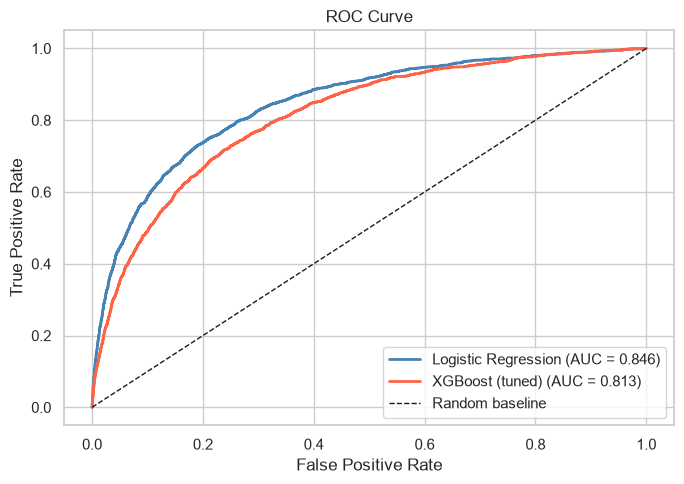

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))

for probs, label, color in [
    (lr_probs,  'Logistic Regression', 'steelblue'),
    (xgb_probs, 'XGBoost (tuned)',     'tomato'),
]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    ax.plot(fpr, tpr, lw=2, label=f'{label} (AUC = {auc:.3f})', color=color)

ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random baseline')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve')
ax.legend()
plt.tight_layout()
plt.savefig('../reports/figures/roc_curve.png', dpi=150)
plt.show()

## Precision-Recall Curve

More informative than ROC when defaults are rare (6.7%).
High precision = fewer false alarms. High recall = catching more actual defaults.

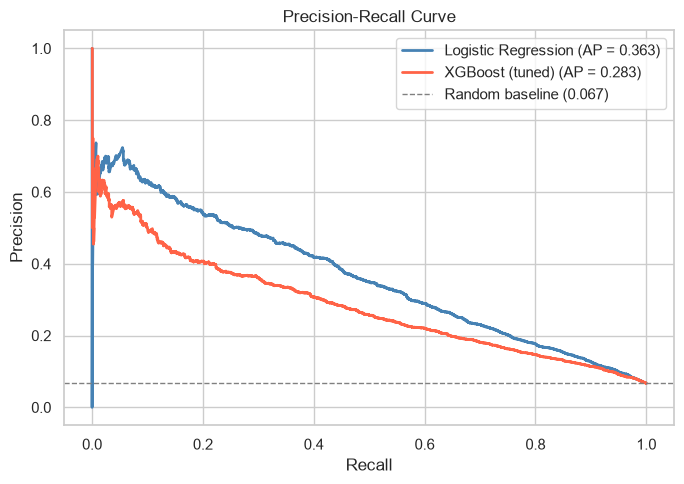

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))

for probs, label, color in [
    (lr_probs,  'Logistic Regression', 'steelblue'),
    (xgb_probs, 'XGBoost (tuned)',     'tomato'),
]:
    precision, recall, _ = precision_recall_curve(y_test, probs)
    ap = average_precision_score(y_test, probs)
    ax.plot(recall, precision, lw=2, label=f'{label} (AP = {ap:.3f})', color=color)

ax.axhline(y_test.mean(), color='gray', linestyle='--', lw=1, label=f'Random baseline ({y_test.mean():.3f})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve')
ax.legend()
plt.tight_layout()
plt.savefig('../reports/figures/pr_curve.png', dpi=150)
plt.show()

## Confusion Matrix — Logistic Regression

Using threshold 0.5 by default. In a real lending context you'd tune this — lower threshold = catch more defaults but more false positives.

Classification Report — Logistic Regression
              precision    recall  f1-score   support

  No Default       0.97      0.83      0.90     27995
     Default       0.23      0.70      0.35      2005

    accuracy                           0.82     30000
   macro avg       0.60      0.77      0.62     30000
weighted avg       0.93      0.82      0.86     30000



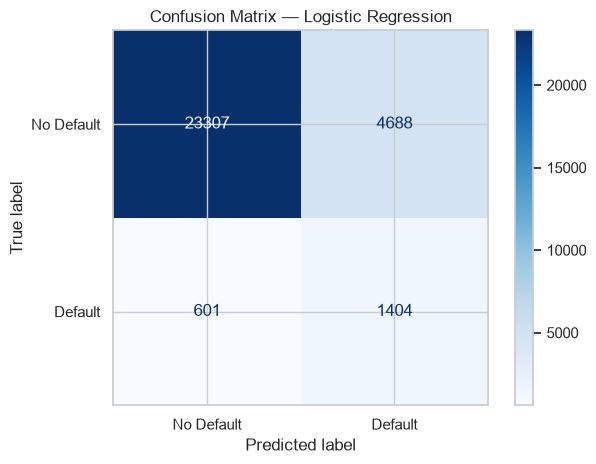

In [6]:
lr_preds = lr_model.predict(X_test_scaled)

print('Classification Report — Logistic Regression')
print(classification_report(y_test, lr_preds, target_names=['No Default', 'Default']))

cm = confusion_matrix(y_test, lr_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Default', 'Default'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix — Logistic Regression')
plt.tight_layout()
plt.savefig('../reports/figures/confusion_matrix_lr.png', dpi=150)
plt.show()

## SHAP — Feature Explainability (XGBoost)

Using XGBoost for SHAP because TreeExplainer is exact and fast for tree models.
This tells us *which features* drive the default prediction and *in which direction*.

In [7]:
# use a sample for speed — SHAP on 30k rows takes a while
sample_idx = np.random.choice(len(X_test_scaled), size=2000, replace=False)
X_test_sample = pd.DataFrame(X_test_scaled[sample_idx], columns=feature_names)

explainer   = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_sample)

print('SHAP values computed. Shape:', shap_values.shape)

SHAP values computed. Shape: (2000, 12)


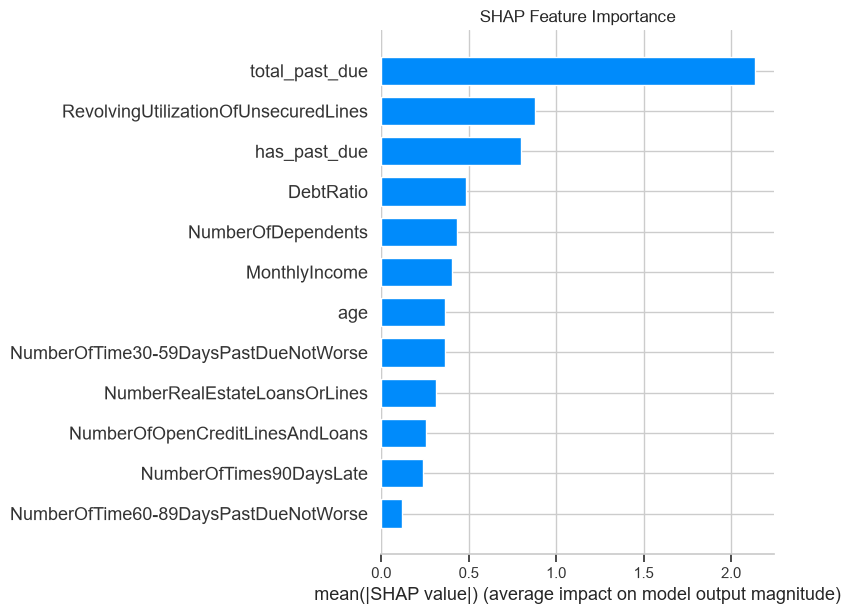

In [8]:
# bar plot — mean absolute SHAP value per feature (importance)
shap.summary_plot(shap_values, X_test_sample, plot_type='bar', show=False)
plt.title('SHAP Feature Importance')
plt.tight_layout()
plt.savefig('../reports/figures/shap_importance.png', dpi=150, bbox_inches='tight')
plt.show()

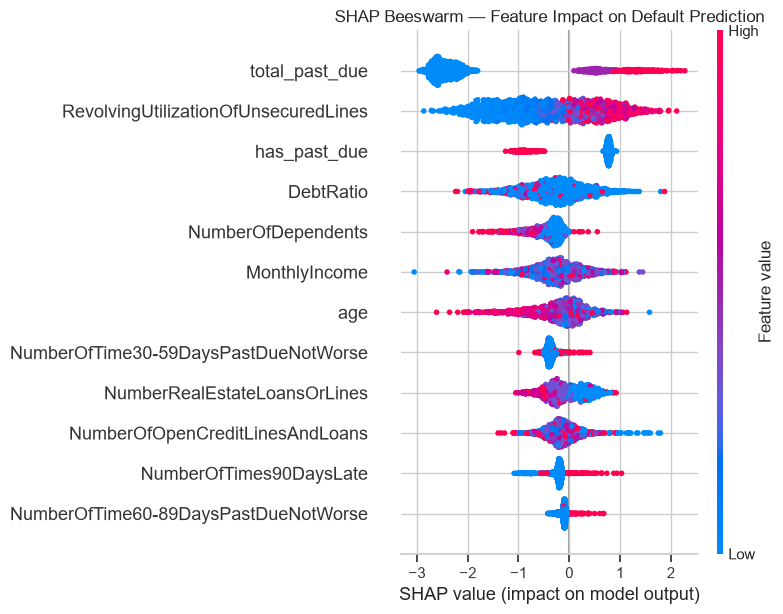

In [9]:
# beeswarm — shows direction of impact, not just magnitude
# red = high feature value, blue = low feature value
shap.summary_plot(shap_values, X_test_sample, show=False)
plt.title('SHAP Beeswarm — Feature Impact on Default Prediction')
plt.tight_layout()
plt.savefig('../reports/figures/shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()

## Key findings

**Metrics — Logistic Regression (test set, 30,000 rows):**
- AUC-ROC: **0.846** — XGBoost (tuned) scored 0.813. Simpler model wins on unseen data.
- Average Precision: **0.363** vs random baseline of 0.067 — about 5× above chance

**Confusion matrix at threshold 0.5:**
- Caught **1,404 out of 2,005 actual defaults** (70% recall on the minority class)
- 4,688 non-defaulters flagged as risky (false alarms — a trade-off you can tune via threshold)
- Only 601 actual defaults slipped through undetected

**SHAP top features (XGBoost, 2,000 test samples):**
- `total_past_due` — by far the strongest signal; any history of late payments dominates the prediction
- `RevolvingUtilizationOfUnsecuredLines` — high credit utilization strongly predicts default
- `has_past_due` — even the binary yes/no flag carries serious weight

**Why precision-recall matters more than accuracy here:**
- 93.3% of borrowers don't default → predicting 'no default' always gives 93.3% accuracy but catches 0 defaults
- At threshold 0.5: overall accuracy drops to 82%, but recall on the default class is 70% — that's the real win
- In lending, a missed default (false negative) is far more costly than a false alarm — recall is what we optimize for